# 05 – Price or unit cost? Per-ton analysis of the cement segment

**Aim:** How much of the 2022 → 2025 increase in the cement margin shows up on the per-ton price (revenue) side, and how much on the per-ton cost side?
- *Price (revenue per ton):* Largely market-driven; not controllable.
- *Unit cost:* Partly controllable.

**Data:** `output/tables/` – annual_master, sales_volumes_annual, fx_rates_annual, cement_ppi_monthly (src/12). No PDFs are read.

**Decisions:**
- **2019 excluded.** 2019 sales volumes were excluded from the per-ton analysis: grey cement and clinker sales have the same value (3.50 million tons), probably an assignment error. 2019 segment data are also problematic.
- **Sector data as context only.** The `sector_*` values are fragmented and mostly partial-year; they are not used in calculations.
- **Cement PPI:** The TÜİK domestic PPI sub-item **TP.TUFE1YI.T69 "Çimento, kireç ve alçı" (cement, lime and plaster; NACE 23.5)** was found in EVDS and fetched (src/12_fetch_cement_ppi.py). NACE 23.51 (cement only) does not exist as a separate series; the series used also includes lime and plaster.

## Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "output" / "tables"
FIGS = ROOT / "output" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 110)

C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
C_GREY, C_INK, C_MUTED = "#8a8985", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C_MUTED, "axes.labelcolor": C_INK,
    "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "lines.linewidth": 2, "legend.frameon": False,
})
YEARS = list(range(2016, 2026))

In [2]:
master = pd.read_csv(TABLES / "annual_master.csv")
own = master[(master["view"] == "own") & master["year"].between(2016, 2025)].set_index("year").sort_index()
sales = pd.read_csv(TABLES / "sales_volumes_annual.csv")
ppi = pd.read_csv(TABLES / "cement_ppi_monthly.csv")
rates = pd.read_csv(TABLES / "fx_rates_annual.csv")
usd_avg = rates[(rates["item"] == "fx_usd_try_average") & (rates["period"] == "FY")].set_index("year")["value"]
# sales: the year's primary value (own report; otherwise the following report)
prim = sales[(sales["kind"] == "company") & (~sales["restated"] | sales["method"].str.startswith("no value in own report"))]
vols = prim.pivot_table(index="year", columns="item", values="value", aggfunc="first")
vols

item,cac_sales,cement_sales_total,clinker_sales,export_sales_total,grey_cement_sales,ready_mix_sales,white_cement_sales
year,,,,,,,
2016,NaN,NaN,411124.0,NaN,4534562.0,2823480.0,1059720.0
2017,NaN,NaN,749028.0,1600000.0,5252544.0,3440770.0,1127240.0
2018,33000.0,NaN,596205.0,NaN,4562779.0,2741393.0,1273107.0
2019,35100.0,NaN,3500000.0,NaN,3500000.0,1300000.0,1200000.0
2020,40800.0,NaN,1400000.0,NaN,4400000.0,2000000.0,1300000.0
2021,46900.0,NaN,1700000.0,NaN,4220000.0,1940000.0,1390000.0
2022,53310.0,NaN,1700000.0,NaN,3450000.0,1650000.0,1260000.0
2023,59220.0,6660000.0,790000.0,NaN,3930000.0,1800000.0,1720000.0
2024,NaN,6870000.0,NaN,NaN,NaN,2480000.0,NaN


## 1. Market indicator: cement producer price index (PPI)

- **Series:** TP.TUFE1YI.T69, monthly; the annual average is used.
- **Real change:** (1 + PPI change) / (1 + CPI change) − 1.
- **Dollar equivalent:** Annual average index / annual average USD rate. Shown as an index (2016 = 100) in the same chart as revenue per ton (section 4).

In [3]:
fy = ppi[ppi["period"] == "FY"].pivot_table(index="year", columns="item", values="value").loc[2016:2025]
fy["cement_ppi_usd"] = fy["cement_ppi_annual_avg"] / usd_avg.reindex(fy.index)
fy["cement_ppi_usd_index_2016"] = fy["cement_ppi_usd"] / fy.loc[2016, "cement_ppi_usd"] * 100
fy.round(2)

item,cement_ppi_annual_avg,cement_ppi_nominal_yoy_pct,cement_ppi_real_yoy_pct,cpi_annual_avg_yoy_pct,cement_ppi_usd,cement_ppi_usd_index_2016
year,,,,,,
2016,277.94,-1.81,-8.89,7.78,92.00,100.00
2017,294.41,5.92,-4.70,11.14,80.76,87.79
2018,367.16,24.71,7.20,16.33,76.44,83.09
2019,398.09,8.43,-5.86,15.18,70.20,76.31
2020,417.09,4.77,-6.69,12.28,59.51,64.68
2021,632.12,51.56,26.72,19.60,71.14,77.33
2022,1887.15,198.54,73.26,72.31,113.93,123.84
2023,3037.16,60.94,4.60,53.86,127.91,139.04
2024,4113.04,35.42,-14.56,58.51,125.43,136.34


**What we see:**
- The cement PPI rose by +27% in real terms in 2021 and by +73% in real terms in 2022. Real −15% in 2024, real −12% in 2025.
- The dollar-equivalent PPI index (2016 = 100) peaks in 2022 and declines in 2024–2025.
- This points to a period after 2022 in which market cement prices lagged inflation.

## 2. Per-ton indicators (cement segment)

**Sales volume:**
- 2016–2023: grey + white + CAC + clinker sales. CAC is missing in 2016–2017, so ~30 thousand tons are missing in those years.
- 2024–2025: total cement sales ("clinker included"). In 2025 the same page also has an "excluding Mannok" footnote and it is unclear which line it belongs to; flagged.
- 2023: so that it is consistent with the 2016–2023 definition, the sum of the components was used (6.50 million tons). The total cement value in the 2024 report is 6.66 million tons.
- 2019 excluded.

**Per-ton indicators:** Cement segment revenue, cost of sales and gross profit are divided by sales volume. USD conversion: average in nominal years, year-end rate in IAS 29 years.

**Scope notes:**
- **2016–2020:** Segment financials include the international white cement companies (a discontinued operation in the 2020 report). The scope of the integrated report volumes is not clearly stated in these years; numerator and denominator may not fully overlap.
- **2021–2022:** International white cement was in SBS; not in the segment. Volumes cover Turkey.
- **After 2023:** SBS is in the cement segment and in the volumes (white cement 1.72 million tons).
- **2024–2025:** The segment and volume scope of Mannok's cement activity is unclear.
- **Inter-segment sales:** 2016–2018 segment revenue includes internal sales to the ready-mix concrete segment (before elimination).

In [4]:
vol = pd.Series(np.nan, index=YEARS)
for y in range(2016, 2024):
    vol[y] = vols.loc[y, ["grey_cement_sales", "white_cement_sales", "clinker_sales"]].sum() + np.nan_to_num(vols.loc[y].get("cac_sales", np.nan))
for y in (2024, 2025):
    vol[y] = vols.loc[y, "cement_sales_total"]
vol[2019] = np.nan  # decision: 2019 volumes excluded from the per-ton analysis

rate = own["usd_try_rate_used"]
pt = pd.DataFrame({
    "basis": own["basis"],
    "volume_mn_t": vol / 1e6,
    "cement_revenue_mn_try": own["segment_cement_revenue"] / 1e6,
    "cement_cos_mn_try": own["segment_cement_cost_of_sales"] / 1e6,
    "rev_per_t_try": own["segment_cement_revenue"] / vol,
    "cos_per_t_try": own["segment_cement_cost_of_sales"] / vol,
    "rev_per_t_usd": own["segment_cement_revenue"] / rate / vol,
    "cos_per_t_usd": own["segment_cement_cost_of_sales"] / rate / vol,
    # energy/ton: total energy cost / cement + clinker sales (no energy by segment; approximate)
    "energy_per_t_usd": own["energy_cost"] / rate / vol,
    "usd_rate": rate, "usd_rate_basis": own["usd_rate_basis"],
})
pt["gp_per_t_try"] = pt["rev_per_t_try"] - pt["cos_per_t_try"]
pt["gp_per_t_usd"] = pt["rev_per_t_usd"] - pt["cos_per_t_usd"]
pt["other_cost_per_t_usd"] = pt["cos_per_t_usd"] - pt["energy_per_t_usd"]
pt["cement_margin_pct"] = pt["gp_per_t_usd"] / pt["rev_per_t_usd"] * 100
pt.drop(columns=["usd_rate_basis"]).round(1)

,basis,volume_mn_t,cement_revenue_mn_try,cement_cos_mn_try,rev_per_t_try,cos_per_t_try,rev_per_t_usd,cos_per_t_usd,energy_per_t_usd,usd_rate,gp_per_t_try,gp_per_t_usd,other_cost_per_t_usd,cement_margin_pct
2016,nominal,6.0,974.2,592.2,162.2,98.6,53.7,32.6,14.8,3.0,63.6,21.1,17.9,39.2
2017,nominal,7.1,1257.0,846.7,176.3,118.8,48.4,32.6,13.4,3.6,57.6,15.8,19.2,32.6
2018,nominal,6.5,1449.7,1035.5,224.2,160.2,46.7,33.3,15.0,4.8,64.1,13.3,18.3,28.6
2019,nominal,NaN,1873.1,1625.6,NaN,NaN,NaN,NaN,NaN,5.7,NaN,NaN,NaN,NaN
2020,nominal,7.1,1799.2,1334.7,252.0,186.9,35.9,26.7,14.4,7.0,65.0,9.3,12.3,25.8
2021,nominal,7.4,3321.7,2655.7,451.5,361.0,50.8,40.6,21.4,8.9,90.5,10.2,19.3,20.1
2022,nominal,6.5,7510.8,6145.7,1162.1,950.9,70.2,57.4,33.9,16.6,211.2,12.8,23.5,18.2
2023,tms29,6.5,17726.1,14116.1,2727.4,2172.0,92.8,73.9,26.3,29.4,555.4,18.9,47.6,20.4
2024,tms29,6.9,21513.9,16550.7,3131.6,2409.1,88.9,68.4,25.9,35.2,722.4,20.5,42.5,23.1
2025,tms29,8.1,31479.4,24782.9,3886.3,3059.6,90.7,71.4,20.8,42.9,826.7,19.3,50.6,21.3


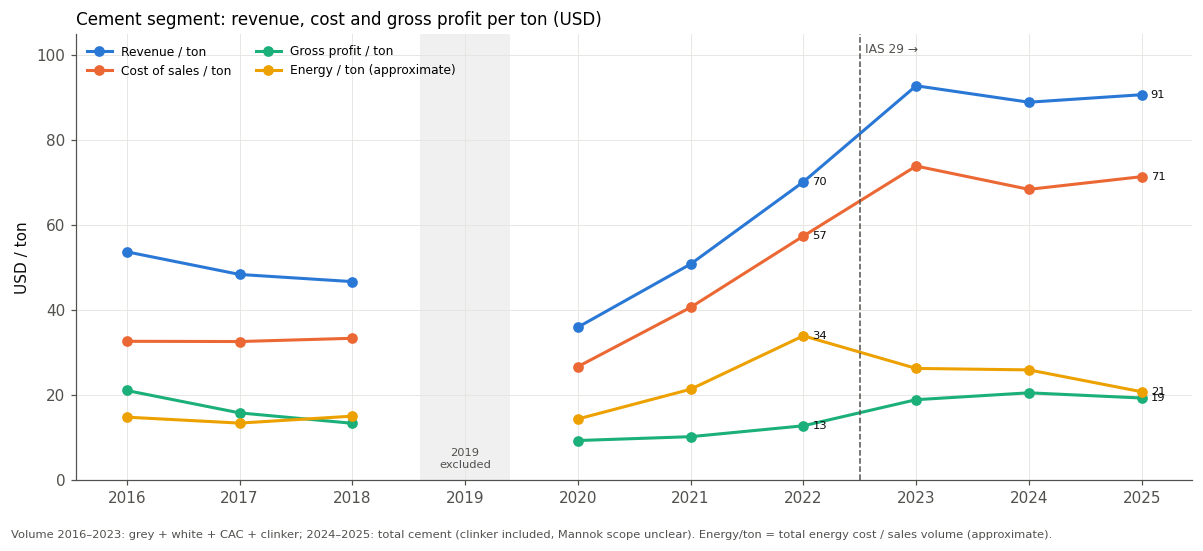

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.8))
yrs = [y for y in YEARS if y != 2019]
for col, lab, c in [("rev_per_t_usd", "Revenue / ton", C_BLUE), ("cos_per_t_usd", "Cost of sales / ton", C_ORANGE),
                    ("gp_per_t_usd", "Gross profit / ton", C_AQUA), ("energy_per_t_usd", "Energy / ton (approximate)", C_YELLOW)]:
    ax.plot(YEARS, pt.loc[YEARS, col], marker="o", color=c, label=lab)  # 2019 NaN: the line breaks
    for y in (2022, 2025):
        ax.text(y + 0.08, pt.loc[y, col], f"{pt.loc[y, col]:.0f}", fontsize=7.5, color=C_INK, va="center")
ax.axvline(2022.5, color=C_MUTED, linestyle="--", linewidth=1)
ax.text(2022.55, 0.98, "IAS 29 →", transform=ax.get_xaxis_transform(), fontsize=8, color=C_MUTED, va="top")
ax.axvspan(2018.6, 2019.4, color=C_GREY, alpha=0.12, linewidth=0)
ax.text(2019, 3, "2019\nexcluded", ha="center", fontsize=7.5, color=C_MUTED)
ax.set_xticks(YEARS); ax.set_ylim(0, 105); ax.set_ylabel("USD / ton")
ax.set_title("Cement segment: revenue, cost and gross profit per ton (USD)", loc="left", fontsize=11)
ax.legend(loc="upper left", fontsize=8, ncol=2)
fig.text(0.01, -0.03, "Volume 2016–2023: grey + white + CAC + clinker; 2024–2025: total cement (clinker included, Mannok scope unclear). "
         "Energy/ton = total energy cost / sales volume (approximate).", fontsize=7.5, color=C_MUTED)
fig.tight_layout()
fig.savefig(FIGS / "05_per_ton_cement.png", bbox_inches="tight")
plt.show()

**What we see:**
- **Revenue / ton:** ~54 USD in 2016; a ~36 USD trough in 2020, ~70 in 2022, ~89–93 USD in 2023–2025.
- **Gross profit / ton:** ~21 USD in 2016, 9–13 USD in 2020–2022, 19–21 USD in 2023–2025.
- **Cost of sales / ton:** rises to ~74 USD in 2023; the same year as the IAS 29 transition.

## 3. Price-cost decomposition (USD / ton)

**Δ(gross profit/ton) = Δ(revenue/ton) − Δ(energy/ton) − Δ(other cost/ton)**

- *Other cost/ton* = cost of sales/ton − energy/ton.
- *Energy/ton* is approximate: total energy cost is group-wide (including ready-mix concrete and building materials); there is no energy by segment.
- The energy → other production classification change in 2025 (notebook 02) affects the split between energy and other cost; it does not affect gross profit/ton.

**Periods:**
- **(a) 2022 (nominal, own report) → 2025:** Spans the series change.
  - 2022 amounts are nominal, converted at the annual average rate.
  - 2025 amounts are IAS 29, converted at the year-end rate; because IAS 29 amounts are converted at the year-end rate, the 2025 dollar amounts may be slightly high.
  - IAS 29 indexes inventory and depreciation in cost of sales, so it may push cost/ton up.
  - The scope also differs: no SBS in 2022, SBS included in 2025.
- **(b) 2023 → 2025:** Within the same IAS 29 series; a cleaner comparison. Still, the two years are in the year-end purchasing power of different reports.
- **(c) 2022r → 2023:** Within the same report (2023 annual); section 3b.

In [6]:
def decompose(y0, y1):
    a, b = pt.loc[y0], pt.loc[y1]
    out = pd.Series({
        "gp_per_t_start": a["gp_per_t_usd"],
        "d_revenue_per_t": b["rev_per_t_usd"] - a["rev_per_t_usd"],
        "minus_d_energy_per_t": -(b["energy_per_t_usd"] - a["energy_per_t_usd"]),
        "minus_d_other_cost_per_t": -(b["other_cost_per_t_usd"] - a["other_cost_per_t_usd"]),
        "gp_per_t_end": b["gp_per_t_usd"],
    })
    out["d_gp_per_t"] = out["gp_per_t_end"] - out["gp_per_t_start"]
    assert np.isclose(out["d_revenue_per_t"] + out["minus_d_energy_per_t"] + out["minus_d_other_cost_per_t"], out["d_gp_per_t"])
    out["margin_start_pct"], out["margin_end_pct"] = a["cement_margin_pct"], b["cement_margin_pct"]
    return out

PERIODS = {"(a) 2022 → 2025 (incl. series change)": (2022, 2025), "(b) 2023 → 2025 (within IAS 29)": (2023, 2025)}
dec = pd.DataFrame({p: decompose(*yy) for p, yy in PERIODS.items()})
dec.round(2)

,(a) 2022 → 2025 (incl. series change),(b) 2023 → 2025 (within IAS 29)
gp_per_t_start,12.75,18.89
d_revenue_per_t,20.51,-2.11
minus_d_energy_per_t,13.17,5.49
minus_d_other_cost_per_t,-27.14,-2.99
gp_per_t_end,19.29,19.29
d_gp_per_t,6.54,0.39
margin_start_pct,18.18,20.37
margin_end_pct,21.27,21.27


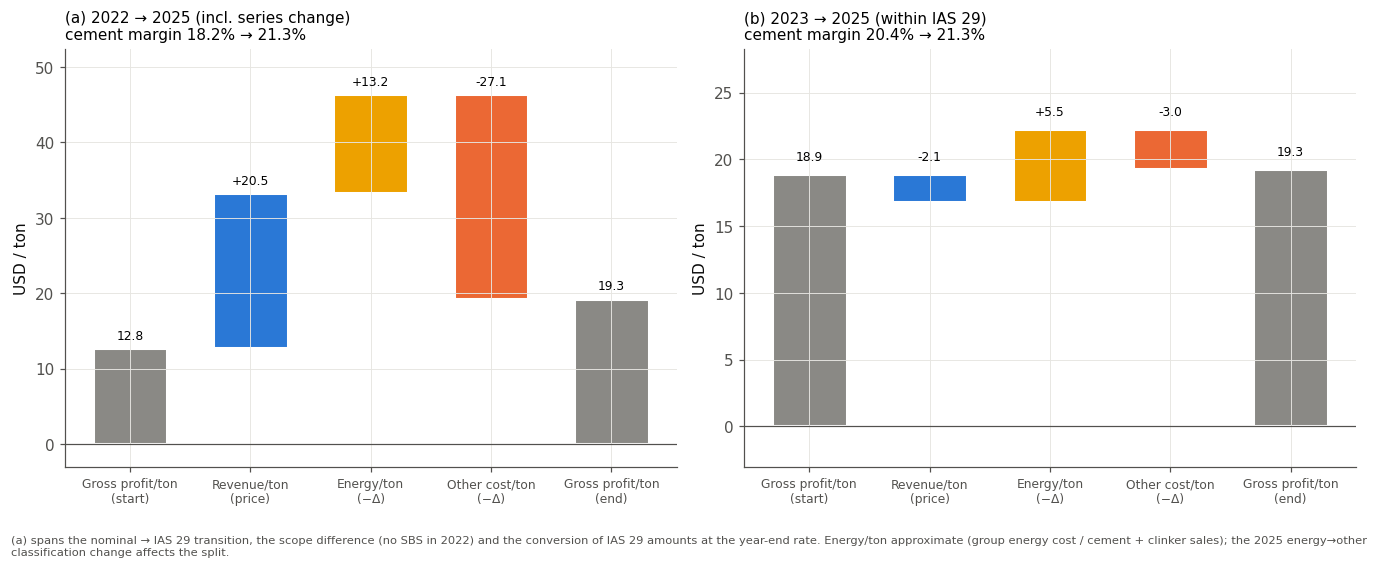

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
STEPS = [("gp_per_t_start", "Gross profit/ton\n(start)", C_GREY, "total"), ("d_revenue_per_t", "Revenue/ton\n(price)", C_BLUE, "step"),
         ("minus_d_energy_per_t", "Energy/ton\n(−Δ)", C_YELLOW, "step"), ("minus_d_other_cost_per_t", "Other cost/ton\n(−Δ)", C_ORANGE, "step"),
         ("gp_per_t_end", "Gross profit/ton\n(end)", C_GREY, "total")]
for ax, (p, (y0, y1)) in zip(axes, PERIODS.items()):
    s = dec[p]; level = 0.0; tops = []
    for i, (k, lab, c, kind) in enumerate(STEPS):
        v = s[k]
        if kind == "total":
            ax.bar(i, v, color=c, width=0.62, edgecolor="white", linewidth=2); level = v; tops.append(v)
            ax.text(i, v + 0.8, f"{v:.1f}", ha="center", va="bottom", fontsize=8)
        else:
            ax.bar(i, v, bottom=level, color=c, width=0.62, edgecolor="white", linewidth=2)
            ax.text(i, level + max(v, 0) + 0.8, f"{v:+.1f}", ha="center", va="bottom", fontsize=8)
            level += v; tops += [level, level - v]
    ax.axhline(0, color=C_MUTED, linewidth=0.8)
    ax.set_xticks(range(len(STEPS))); ax.set_xticklabels([x[1] for x in STEPS], fontsize=8)
    ax.set_ylim(min(0, min(tops)) - 3, max(tops) + 6)
    ax.set_ylabel("USD / ton")
    ax.set_title(f"{p}\ncement margin {s['margin_start_pct']:.1f}% → {s['margin_end_pct']:.1f}%", loc="left", fontsize=10)
fig.text(0.01, -0.06, "(a) spans the nominal → IAS 29 transition, the scope difference (no SBS in 2022) and the conversion of IAS 29 amounts at the year-end rate. "
         "Energy/ton approximate (group energy cost / cement + clinker sales); the 2025 energy→other classification change affects the split.",
         fontsize=7.5, color=C_MUTED, wrap=True)
fig.tight_layout()
fig.savefig(FIGS / "05_price_cost_waterfall.png", bbox_inches="tight")
plt.show()

**What we see:**
- **(a) 2022 → 2025:** Gross profit/ton goes from ~12.8 to ~19.3 USD (+6.5). This change comes together with the following components:
  - Revenue/ton: +20.5 USD.
  - Lower energy/ton: +13.1 USD.
  - Higher other cost/ton: −27.1 USD.

  The jump in other cost does not arise in 2023 but in the IAS 29 and SBS-inclusive restatement of 2022 (2022 nominal 23.5 → 2022r 46.2 USD/ton; section 3b). Because this comparison includes the series change and a scope difference, the magnitudes should be read with caution.
- **(b) 2023 → 2025 (same series):** Gross profit/ton is almost unchanged (+0.4 USD).
  - Revenue/ton: −2.1 USD.
  - Lower energy/ton: +5.5 USD.
  - Higher other cost/ton: −3.0 USD.

  The margin increase (20.4% → 21.3%) comes mainly together with the fall in energy cost; price and other costs offset part of it.

## 3b. Missing period: 2022r → 2023 (within the same IAS 29 series)

The large jump in the cement margin is between 2022r and 2023 (11.5% → 20.4%). This period can be decomposed using two columns of the same report (2023 annual).

- **2022r:** `view = restated_in_2023` in annual_master (IAS 29, SBS included, restated under common-control accounting). Volumes: the values the 2023 report gives for 2022 in sales_volumes_annual (`restated = True`, `report_year = 2023`): grey 3.57 + white 1.59 + clinker 1.46 million tons.
- **2023:** own report (with the definition in section 2: grey + white + CAC + clinker).
- **Same purchasing power, same rate:** The amounts of both years are in December 2023 purchasing power and are converted to dollars at the same rate (2023 year-end). The change in dollar terms therefore actually shows the **real** change in December 2023 TRY; the limitation of converting IAS 29 amounts at the year-end rate affects both years equally.

**Limitations:**
- **CAC missing:** The 2023 report does not give CAC volumes for 2022. The 2022r volume has no CAC (~53 thousand tons in the 2022 own report, ~1% of the total); per-ton indicators for 2022r may be biased upwards by this amount. As a sensitivity, 2023 was also computed excluding CAC.
- **Scope:** 2022r may include the Central Anatolia plants (Niğde, Kayseri, Ankara) sold on 28.07.2022 for part of the year; the report does not state whether the volumes cover these plants.
- **Energy/ton approximate:** As in section 3, group energy cost / cement + clinker volume.

In [8]:
# 2022r: restated 2022 in the 2023 report (IAS 29); 2023: own report – both at the same rate
r22 = master[(master["year"] == 2022) & (master["view"] == "restated_in_2023")].iloc[0]
r23 = master[(master["year"] == 2023) & (master["view"] == "own")].iloc[0]
assert r22["usd_try_rate_used"] == r23["usd_try_rate_used"] and r22["basis"] == r23["basis"] == "tms29"
v22r = sales[(sales["kind"] == "company") & (sales["year"] == 2022) & sales["restated"] & (sales["report_year"] == 2023)].set_index("item")["value"]
assert set(v22r.index) == {"grey_cement_sales", "white_cement_sales", "clinker_sales"}  # no CAC
v23_items = vols.loc[2023, ["grey_cement_sales", "white_cement_sales", "clinker_sales", "cac_sales"]]

def per_ton(r, volume):
    k = r["usd_try_rate_used"]
    out = pd.Series({
        "volume_mn_t": volume / 1e6,
        "rev_per_t_usd": r["segment_cement_revenue"] / k / volume,
        "cos_per_t_usd": r["segment_cement_cost_of_sales"] / k / volume,
        "energy_per_t_usd": r["energy_cost"] / k / volume,
    })
    out["other_cost_per_t_usd"] = out["cos_per_t_usd"] - out["energy_per_t_usd"]
    out["gp_per_t_usd"] = out["rev_per_t_usd"] - out["cos_per_t_usd"]
    out["cement_margin_pct"] = out["gp_per_t_usd"] / out["rev_per_t_usd"] * 100
    return out

pt_r = pd.DataFrame({
    "2022r (no CAC)": per_ton(r22, v22r.sum()),
    "2023": per_ton(r23, v23_items.sum()),
    "2023 (excl. CAC, sensitivity)": per_ton(r23, v23_items.drop("cac_sales").sum()),
}).T
assert np.isclose(pt_r.loc["2023", "rev_per_t_usd"], pt.loc[2023, "rev_per_t_usd"])  # consistent with section 2
pd.concat([v22r.rename("2022r"), v23_items.rename("2023")], axis=1).div(1e6).round(3)


,2022r,2023
item,,
clinker_sales,1.46,0.790
grey_cement_sales,3.57,3.930
white_cement_sales,1.59,1.720
cac_sales,NaN,0.059


In [9]:
pt_r.round(2)

,volume_mn_t,rev_per_t_usd,cos_per_t_usd,energy_per_t_usd,other_cost_per_t_usd,gp_per_t_usd,cement_margin_pct
2022r (no CAC),6.62,97.92,86.65,40.45,46.20,11.27,11.51
2023,6.50,92.78,73.88,26.25,47.63,18.89,20.37
"2023 (excl. CAC, sensitivity)",6.44,93.63,74.56,26.49,48.07,19.07,20.37


In [10]:
def decompose_rows(a, b):
    out = pd.Series({
        "gp_per_t_start": a["gp_per_t_usd"],
        "d_revenue_per_t": b["rev_per_t_usd"] - a["rev_per_t_usd"],
        "minus_d_energy_per_t": -(b["energy_per_t_usd"] - a["energy_per_t_usd"]),
        "minus_d_other_cost_per_t": -(b["other_cost_per_t_usd"] - a["other_cost_per_t_usd"]),
        "gp_per_t_end": b["gp_per_t_usd"],
    })
    out["d_gp_per_t"] = out["gp_per_t_end"] - out["gp_per_t_start"]
    assert np.isclose(out["d_revenue_per_t"] + out["minus_d_energy_per_t"] + out["minus_d_other_cost_per_t"], out["d_gp_per_t"])
    out["margin_start_pct"], out["margin_end_pct"] = a["cement_margin_pct"], b["cement_margin_pct"]
    return out

dec_r = pd.DataFrame({
    "(c) 2022r → 2023": decompose_rows(pt_r.loc["2022r (no CAC)"], pt_r.loc["2023"]),
    "(c') sensitivity: 2023 excl. CAC": decompose_rows(pt_r.loc["2022r (no CAC)"], pt_r.loc["2023 (excl. CAC, sensitivity)"]),
})
dec_r.round(2)


,(c) 2022r → 2023,(c') sensitivity: 2023 excl. CAC
gp_per_t_start,11.27,11.27
d_revenue_per_t,-5.14,-4.28
minus_d_energy_per_t,14.20,13.95
minus_d_other_cost_per_t,-1.43,-1.87
gp_per_t_end,18.89,19.07
d_gp_per_t,7.63,7.80
margin_start_pct,11.51,11.51
margin_end_pct,20.37,20.37


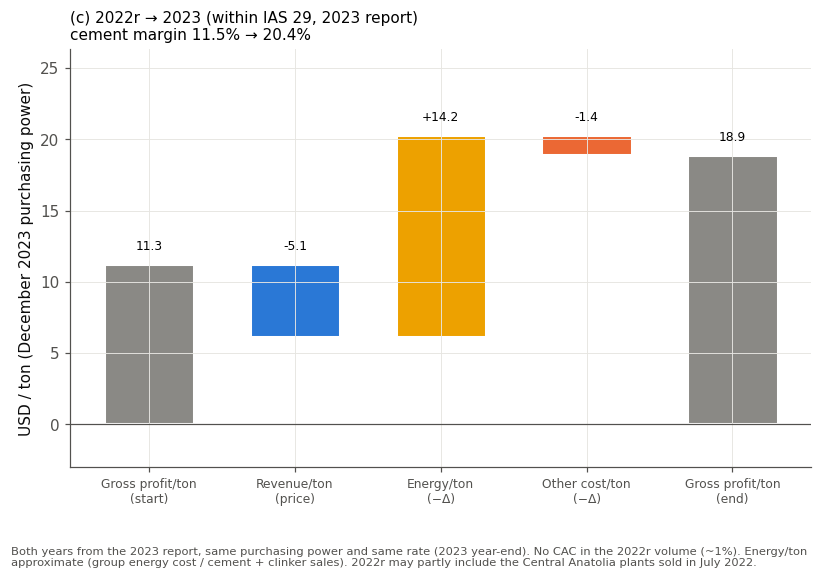

In [11]:
s = dec_r["(c) 2022r → 2023"]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
level = 0.0; tops = []
for i, (k, lab, c, kind) in enumerate(STEPS):
    v = s[k]
    if kind == "total":
        ax.bar(i, v, color=c, width=0.62, edgecolor="white", linewidth=2); level = v; tops.append(v)
        ax.text(i, v + 0.8, f"{v:.1f}", ha="center", va="bottom", fontsize=8)
    else:
        ax.bar(i, v, bottom=level, color=c, width=0.62, edgecolor="white", linewidth=2)
        ax.text(i, level + max(v, 0) + 0.8, f"{v:+.1f}", ha="center", va="bottom", fontsize=8)
        level += v; tops += [level, level - v]
ax.axhline(0, color=C_MUTED, linewidth=0.8)
ax.set_xticks(range(len(STEPS))); ax.set_xticklabels([x[1] for x in STEPS], fontsize=8)
ax.set_ylim(min(0, min(tops)) - 3, max(tops) + 6)
ax.set_ylabel("USD / ton (December 2023 purchasing power)")
ax.set_title(f"(c) 2022r → 2023 (within IAS 29, 2023 report)\ncement margin {s['margin_start_pct']:.1f}% → {s['margin_end_pct']:.1f}%", loc="left", fontsize=10)
fig.text(0.01, -0.08, "Both years from the 2023 report, same purchasing power and same rate (2023 year-end). No CAC in the 2022r volume (~1%). "
         "Energy/ton approximate (group energy cost / cement + clinker sales). 2022r may partly include the Central Anatolia plants sold in July 2022.",
         fontsize=7.5, color=C_MUTED, wrap=True)
fig.tight_layout()
fig.savefig(FIGS / "05_price_cost_waterfall_2022r_2023.png", bbox_inches="tight")
plt.show()


**What we see (2022r → 2023, same series):**
- Gross profit/ton goes from ~11.3 to ~18.9 USD (+7.6); cement margin 11.5% → 20.4%. This change comes together with the following components:
  - Revenue/ton: −5.1 USD (97.9 → 92.8).
  - Lower energy/ton: +14.2 USD (40.4 → 26.2).
  - Higher other cost/ton: −1.4 USD (46.2 → 47.6).
- **The margin jump comes mainly together with the fall in energy cost.** Revenue per ton declined in real terms; other unit costs stayed roughly flat.
- **The jump in other cost/ton is not in 2023.** The value is 23.5 in 2022 nominal and 46.2 USD for the same year in the 2023 report (2022r). So the large increase in section 3(a) arises with the IAS 29 and SBS-inclusive restatement of 2022; within the same series the 2022r → 2023 increase is only ~1.4 USD.
- **Sales mix:** Clinker sales 1.46 → 0.79 million tons, grey cement 3.57 → 3.93 million tons. Revenue per ton fell despite a mix shifting towards products with higher revenue per ton (no price data by product; cannot be separated).
- **Context:** The reconstruction period after the 6 February 2023 earthquakes; sector data show an increase in domestic consumption in 2023–2024 (section 4). Over the same period Çimsa's revenue per ton fell in real terms; the effect of the earthquake on price or volume cannot be separated with this data.
- **Sensitivity:** Computed with 2023 excluding CAC, revenue/ton is −4.3, energy/ton +14.0 and other cost/ton −1.9 USD (the components change by at most ~0.9 USD); the missing CAC does not change the direction or the ranking of magnitudes of the result.

## 4. Context: market events, cement PPI and sector data

| Period | Event | Note |
|---|---|---|
| 2018 (August) | Currency crisis | Sharp depreciation of the TRY (notebook 03, shock quarter 2018 Q3) |
| 2020 | Pandemic and credit expansion | Credit-driven recovery in housing and construction demand |
| 2021–2022 | Energy crisis | Sharp rise in coal and electricity prices (notebook 01) |
| 6 February 2023 | Kahramanmaraş-centred earthquakes | Reconstruction demand |
| After 2023 | Tight monetary policy | Interest rate hikes, tighter credit conditions |

Revenue per ton and the cement PPI are shown in the same chart as dollar-based indices (2016 = 100). 2019 is not available for Çimsa.

**Comparison limit:** Çimsa's revenue per ton was converted at the year-end rate in IAS 29 years, the PPI at the average rate every year. In addition, Çimsa's revenue includes the mix of white cement, CAC and exports; the PPI is a price indicator weighted towards domestic grey cement in Turkey.

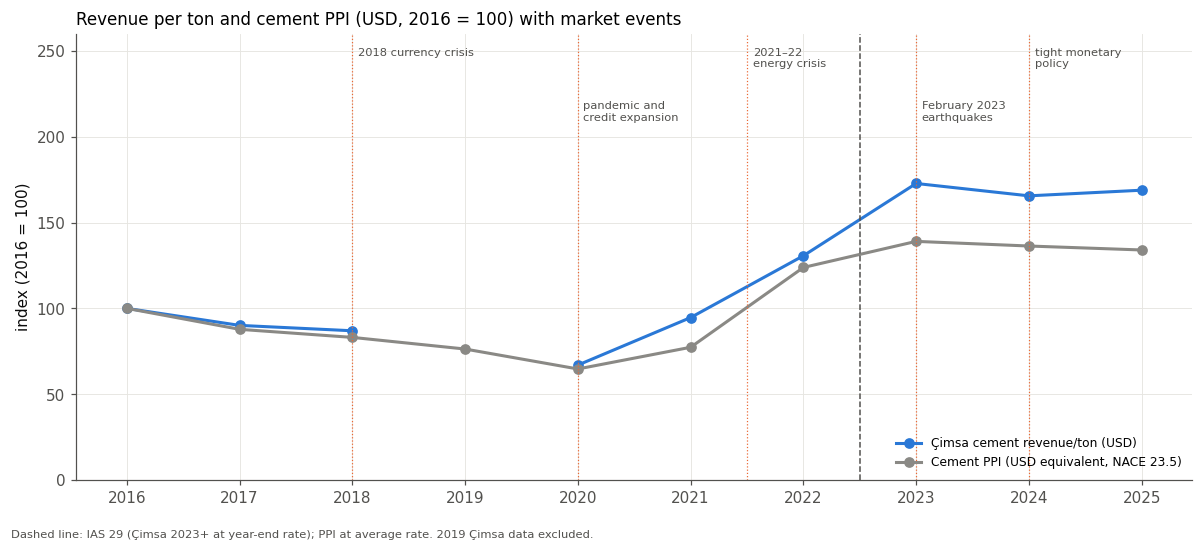

,cimsa_rev_per_t_usd_index,cement_ppi_usd_index
2016,100.0,100.0
2017,90.1,87.8
2018,86.9,83.1
2019,NaN,76.3
2020,66.9,64.7
2021,94.6,77.3
2022,130.7,123.8
2023,172.8,139.0
2024,165.6,136.3
2025,168.9,134.0


In [12]:
idx = pd.DataFrame({
    "cimsa_rev_per_t_usd_index": pt["rev_per_t_usd"] / pt.loc[2016, "rev_per_t_usd"] * 100,
    "cement_ppi_usd_index": fy["cement_ppi_usd_index_2016"],
})
EVENTS = [(2018, "2018 currency crisis"), (2020, "pandemic and\ncredit expansion"), (2021.5, "2021–22\nenergy crisis"),
          (2023, "February 2023\nearthquakes"), (2024, "tight monetary\npolicy")]
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(YEARS, idx.loc[YEARS, "cimsa_rev_per_t_usd_index"], marker="o", color=C_BLUE, label="Çimsa cement revenue/ton (USD)")
ax.plot(YEARS, idx["cement_ppi_usd_index"], marker="o", color=C_GREY, label="Cement PPI (USD equivalent, NACE 23.5)")
for k, (x, t) in enumerate(EVENTS):
    ax.axvline(x, color=C_ORANGE, linewidth=0.8, linestyle=":")
    ax.text(x + 0.05, 0.97 - 0.12 * (k % 2), t, transform=ax.get_xaxis_transform(), fontsize=7.5, color=C_MUTED, va="top")
ax.axvline(2022.5, color=C_MUTED, linestyle="--", linewidth=1)
ax.set_xticks(YEARS); ax.set_ylim(0, 260); ax.set_ylabel("index (2016 = 100)")
ax.set_title("Revenue per ton and cement PPI (USD, 2016 = 100) with market events", loc="left", fontsize=11)
ax.legend(loc="lower right", fontsize=8)
fig.text(0.01, -0.03, "Dashed line: IAS 29 (Çimsa 2023+ at year-end rate); PPI at average rate. 2019 Çimsa data excluded.", fontsize=7.5, color=C_MUTED)
fig.tight_layout()
fig.savefig(FIGS / "05_revenue_per_ton_vs_ppi_events.png", bbox_inches="tight")
plt.show()
idx.round(1)

**Sector data (context only; not used in calculations):** From the narrative text of the integrated reports. The values are fragmented and mostly partial-year (10M = first 10 months, 11M = first 11 months); sources differ by year (TÇMB, TürkÇimento, ÇCSİB, OAİB).

In [13]:
sec = sales[(sales["kind"] == "sector") & (~sales["restated"] | sales["method"].str.startswith("no value in own report"))].copy()
sec["cell"] = (sec["value"] / 1e6).round(1).astype(str) + sec["period"].map(lambda p: "" if p.startswith("FY") else f" ({p})")
LAB = {"sector_cement_production": "Cement production", "sector_clinker_production": "Clinker production",
       "sector_domestic_consumption": "Domestic consumption", "sector_cement_exports": "Cement exports",
       "sector_clinker_exports": "Clinker exports", "sector_cement_clinker_exports": "Cement + clinker exports"}
ctx = sec.pivot_table(index="item", columns="year", values="cell", aggfunc="first").rename(index=LAB).fillna("—")
ctx.index.name = "million tons"
ctx

year,2017,2018,2019,2020,2021,2023,2024
million tons,,,,,,,
Cement + clinker exports,—,—,23.0,31.0,31.0,19.7,—
Cement exports,—,6.3 (10M),10.3 (11M),14.8 (11M),—,—,—
Cement production,—,63.3 (10M),—,72.3,79.0,81.5,84.8
Clinker exports,—,4.7 (10M),10.8 (11M),12.5 (11M),—,—,—
Clinker production,—,61.0 (10M),—,71.8,—,—,—
Domestic consumption,66.3 (11M),56.3 (10M),42.2 (11M),55.6,—,64.9,70.8


**What we see:**
- In dollar terms Çimsa's revenue per ton tracks the PPI closely in 2016–2020; in 2021–2022 both rise together.
- In 2023–2025 Çimsa's revenue per ton is at a higher level than the PPI. This comes together with the difference in conversion method, the inclusion of SBS (white cement) and the export mix; it cannot be separated with this data.
- Sector data show domestic consumption rising in 2023–2024 (64.9 → 70.8 million tons); this coincides with the post-earthquake reconstruction period.

## 5. Assessment (controllable / not controllable)

Two periods can be measured within the same IAS 29 series: **(c) 2022r → 2023** (margin jump) and **(b) 2023 → 2025**.

1. **Not controllable – price:**
   - The cement PPI rose sharply in real terms in 2021–2022 (+27%, +73%) and fell in 2024–2025 (−15%, −12%).
   - Çimsa's revenue per ton fell in both periods within the same series: 2022r → 2023 −5.1 USD/ton (in December 2023 purchasing power, i.e. real), 2023 → 2025 −2.1 USD/ton.
   - 2023 is the reconstruction year after the 6 February earthquakes and sector data show an increase in domestic consumption; even so, no real increase is seen in Çimsa's revenue per ton.
   - The price side shows no positive contribution to the margin increase after 2022.
2. **Largely not controllable – energy cost:**
   - Energy/ton fell by about 14.2 USD in 2022r → 2023 and by about 5.5 USD in 2023 → 2025. In both periods the margin increase comes mainly together with this decline.
   - According to notebook 01, the implied energy price tracks the market with a lag and there is no improvement in physical intensity. This decline comes mainly together with market prices retreating from their 2022 peak.
3. **Partly controllable – other unit costs (raw material, labour, depreciation, other):**
   - Within the same series the per-ton increase is small: ~1.4 USD in 2022r → 2023, ~3 USD in 2023 → 2025. It offset part of the gain on energy.
   - The large increase in the 2022 → 2025 comparison (~27 USD/ton) arises not in 2023 but in the restatement of 2022 (2022 nominal 23.5 → 2022r 46.2 USD/ton): IAS 29 indexation and the inclusion of SBS. It cannot be read as an operational cost increase.
4. **Conclusion:**
   - The 2022r → 2023 jump in the cement margin (11.5% → 20.4%; gross profit/ton +7.6 USD) comes mainly together with the fall in energy cost per ton (+14.2); revenue per ton declined in real terms (−5.1), other unit costs stayed roughly flat (−1.4).
   - In 2023 → 2025 the margin is maintained with a small increase; again the fall in energy offsets the price decline and the rise in other costs.
   - In both periods measured within the same series, the margin improvement comes mainly together with the market-driven fall in energy cost, not with unit costs under the company's control.
   - Limitations: energy/ton is approximate (group-wide); no CAC in the 2022r volume (the result does not change in the sensitivity); 2022r may partly include the Central Anatolia plants sold in July 2022.